# 03 — Modélisation : validation croisée groupée et optimisation

**Règle d'or** : le jeu de test (`test.csv`) n'est **pas chargé** dans ce notebook. Tous les choix (caractéristiques,
modèle, hyperparamètres) sont faits par **validation croisée sur le train**. Le test sera utilisé une seule fois,
au notebook 04.

| Modèle | Rôle | Préparation dans le Pipeline |
|---|---|---|
| `DummyRegressor` | référence plancher : prédit toujours la Mw moyenne du train | — |
| `Ridge` | modèle linéaire régularisé | imputation (médiane) + standardisation |
| `XGBRegressor` | modèle principal (arbres boostés) | aucune (gère les valeurs manquantes) |

Métrique principale : **MAE** (erreur moyenne en unités de magnitude, directement interprétable) ;
garde-fous : **RMSE** (pénalise les grosses erreurs) et **R²**.

⏱ Durée d'exécution : ~15 min

In [ ]:
import sys, time, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict

from src import config as C, dataset as D, modeling as M

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
MODEL_DIR = C.PROJECT_ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)

train = pd.read_csv(C.PROCESSED_DIR / "train.csv")      # <- uniquement le train
y = train[D.TARGET].values
groups = train[D.GROUP].values

feat_A = D.feature_columns(train, spatial=False)
feat_AB_all = D.feature_columns(train, spatial=True)
# 12 stations n'ont jamais de données pendant les 18 h de bruit du train : leurs colonnes sont vides -> retirées
feat_AB = [c for c in feat_AB_all if train[c].notna().any()]
print(f"{len(train)} séismes d'entraînement | famille A : {len(feat_A)} colonnes | "
      f"A+B : {len(feat_AB)} colonnes ({len(feat_AB_all) - len(feat_AB)} colonnes vides retirées)")

4800 séismes d'entraînement | famille A : 61 colonnes | A+B : 322 colonnes (12 colonnes vides retirées)


## 1. Le découpage de la validation croisée

Le découpage train / test a été fait à la génération (notebook 02) : **aucun séisme et aucune heure de bruit en
commun**. Pour la validation croisée, on utilise `GroupKFold` avec comme groupe l'**heure de bruit réel** : tous les
séismes construits avec la même heure de bruit restent dans le **même fold**. Sinon, le modèle pourrait « reconnaître »
un bruit déjà vu et paraître meilleur qu'il ne l'est.

In [ ]:
folds = []
for k, (i_tr, i_va) in enumerate(M.cv_splitter().split(train, y, groups)):
    folds.append({"fold": k + 1, "heures de bruit en validation": sorted(set(groups[i_va]).__iter__()),
                  "séismes train": len(i_tr), "séismes validation": len(i_va),
                  "heures communes train/val": len(set(groups[i_tr]) & set(groups[i_va]))})
pd.DataFrame(folds)

,fold,heures de bruit en validation,séismes train,séismes validation,heures communes train/val
0,1,"[3, 5, 13]",3984,816,0
1,2,"[0, 7, 11]",3987,813,0
2,3,"[2, 8, 10, 15]",3742,1058,0
3,4,"[4, 6, 14, 17]",3742,1058,0
4,5,"[1, 9, 12, 16]",3745,1055,0


## 2. Premier essai : les 3 modèles avec des réglages par défaut

On compare aussi les deux familles de caractéristiques : **A** (61 agrégats sur le réseau) et **A+B** (+ le motif
spatial station par station).

In [ ]:
t0 = time.time()
rows = [M.cv_report(M.make_dummy(), train[feat_A], y, groups, "Dummy (moyenne)")]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    rows += [M.cv_report(M.make_ridge(), train[feat_A], y, groups, "Ridge — A"),
             M.cv_report(M.make_ridge(), train[feat_AB], y, groups, "Ridge — A+B"),
             M.cv_report(M.make_xgb(), train[feat_A], y, groups, "XGBoost défaut — A"),
             M.cv_report(M.make_xgb(), train[feat_AB], y, groups, "XGBoost défaut — A+B")]
first = pd.DataFrame(rows).set_index("modèle")
print(f"({time.time() - t0:.0f} s)")
first.round(3)

(32 s)


,MAE train,MAE val (moy),MAE val (é.-t.),RMSE train,RMSE val (moy),RMSE val (é.-t.),R2 train,R2 val (moy),R2 val (é.-t.),temps ajust. (s)
modèle,,,,,,,,,,
Dummy (moyenne),0.621,0.621,0.007,0.715,0.715,0.007,0.000,-0.001,0.001,0.005
Ridge — A,0.355,0.363,0.012,0.451,0.462,0.016,0.602,0.582,0.028,0.025
Ridge — A+B,0.344,0.384,0.011,0.436,0.489,0.019,0.628,0.530,0.039,0.181
XGBoost défaut — A,0.187,0.305,0.014,0.236,0.393,0.016,0.891,0.697,0.026,0.783
XGBoost défaut — A+B,0.132,0.282,0.009,0.166,0.364,0.012,0.946,0.740,0.016,5.240


**Lecture** :
- **Dummy** : MAE ≈ 0,62. C'est le score « sans rien savoir » : pour une magnitude uniforme sur 2,5 unités, prédire
  toujours le milieu donne en moyenne 2,5 / 4 ≈ 0,625. Tout modèle utile doit faire mieux.
- **Ridge** réduit l'erreur d'environ 40 % ; le motif spatial (A+B) le **dégrade** : 273 colonnes bruitées et une relation
  non linéaire, qu'un modèle linéaire ne peut pas exploiter.
- **XGBoost** est le meilleur, et **profite** du motif spatial (A+B). Mais l'écart entraînement / validation est grand
  (MAE ≈ 0,13 contre ≈ 0,28) : il **sur-apprend**.
- Les écarts-types entre folds sont petits (≈ 0,01) : les différences entre modèles sont nettes.

→ On retient **Ridge sur A** et **XGBoost sur A+B** pour l'optimisation.

## 3. Optimisation de Ridge : la force de régularisation α

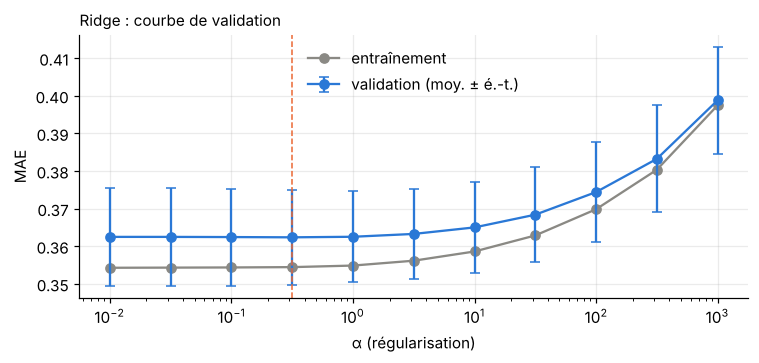

Meilleur α = 0.316 — MAE validation = 0.362


In [ ]:
alphas = np.logspace(-2, 3, 11)
gs_ridge = GridSearchCV(M.make_ridge(), {"model__alpha": alphas}, cv=M.cv_splitter(),
                        scoring="neg_mean_absolute_error", return_train_score=True)
gs_ridge.fit(train[feat_A], y, groups=groups)
r = pd.DataFrame(gs_ridge.cv_results_)
best_alpha = gs_ridge.best_params_["model__alpha"]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(alphas, -r.mean_train_score, "o-", color=C.C_MUTED, label="entraînement")
ax.errorbar(alphas, -r.mean_test_score, yerr=r.std_test_score, fmt="o-", color=C.C_SIGNAL, capsize=3, label="validation (moy. ± é.-t.)")
ax.axvline(best_alpha, color=C.C_NOISY, ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("α (régularisation)"); ax.set_ylabel("MAE")
ax.set_title("Ridge : courbe de validation", loc="left", fontsize=10); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_ridge_alpha.png"); plt.show()
print(f"Meilleur α = {best_alpha:.3g} — MAE validation = {-gs_ridge.best_score_:.3f}")

**Lecture** : les courbes d'entraînement et de validation restent proches (écart ≈ 0,01) : Ridge ne sur-apprend pas,
il est **limité par sa forme linéaire**. Jusqu'à α ≈ 1 la courbe est plate (la régularisation ne change rien) ; au-delà
de α ≈ 30, la MAE augmente nettement (le modèle devient trop contraint).

## 4. Optimisation de XGBoost : recherche aléatoire d'hyperparamètres

On tire 20 combinaisons au hasard (`RandomizedSearchCV`), chacune évaluée par la même validation croisée groupée
(soit 100 entraînements).

| Hyperparamètre | Rôle | Plage |
|---|---|---|
| `n_estimators` | nombre d'arbres | 200 – 900 |
| `learning_rate` | poids de chaque arbre | 0,02 – 0,15 |
| `max_depth` | profondeur (complexité) d'un arbre | 2 – 6 |
| `min_child_weight` | nb minimal d'exemples par feuille (anti sur-apprentissage) | 1 – 30 |
| `subsample` | fraction de séismes vue par arbre | 0,6 – 1 |
| `colsample_bytree` | fraction de caractéristiques vue par arbre | 0,1 – 0,6 |
| `reg_lambda` | régularisation L2 des feuilles | 0,3 – 30 |

In [ ]:
dist = {"model__n_estimators": randint(200, 900), "model__learning_rate": loguniform(0.02, 0.15),
        "model__max_depth": randint(2, 7), "model__min_child_weight": loguniform(1, 30),
        "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.1, 0.5),
        "model__reg_lambda": loguniform(0.3, 30)}
t0 = time.time()
rs = RandomizedSearchCV(M.make_xgb(), dist, n_iter=20, cv=M.cv_splitter(), scoring="neg_mean_absolute_error",
                        return_train_score=True, random_state=C.RANDOM_STATE, n_jobs=1)
rs.fit(train[feat_AB], y, groups=groups)
print(f"Recherche terminée en {(time.time() - t0) / 60:.1f} min")

res = pd.DataFrame(rs.cv_results_)
res["MAE train"] = -res.mean_train_score
res["MAE val"] = -res.mean_test_score
res["é.-t. val"] = res.std_test_score
res["écart val-train"] = res["MAE val"] - res["MAE train"]
pcols = [c for c in res if c.startswith("param_")]
table = res[pcols + ["MAE train", "MAE val", "é.-t. val", "écart val-train", "mean_fit_time"]].sort_values("MAE val")
table.columns = [c.replace("param_model__", "") for c in table.columns]
table.round(3)

Recherche terminée en 9.1 min


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,MAE train,MAE val,é.-t. val,écart val-train,mean_fit_time
16,0.554,0.033,6,6.272,740,0.860,0.631,0.031,0.278,0.008,0.247,15.154
2,0.516,0.031,5,1.866,659,5.017,0.603,0.083,0.279,0.007,0.196,9.508
6,0.215,0.033,5,1.514,708,13.916,0.669,0.091,0.280,0.008,0.189,6.615
9,0.385,0.057,6,3.751,537,3.602,0.835,0.018,0.280,0.008,0.262,10.566
13,0.132,0.037,6,11.960,746,2.640,0.648,0.044,0.281,0.010,0.237,7.023
3,0.112,0.058,3,1.172,899,1.621,0.782,0.139,0.281,0.009,0.142,3.298
11,0.312,0.044,4,1.967,591,8.613,0.909,0.123,0.281,0.007,0.158,4.190
7,0.296,0.029,5,2.887,589,0.782,0.827,0.098,0.282,0.008,0.184,6.262
15,0.314,0.021,6,1.986,440,1.276,0.803,0.106,0.283,0.010,0.177,7.991
18,0.502,0.029,4,3.014,547,1.548,0.963,0.156,0.283,0.009,0.127,5.190


### Choisir sans sur-interpréter : la règle « d'un écart-type »

Les 20 combinaisons donnent des MAE très proches. Prendre aveuglément la meilleure serait choisir sur une différence
**plus petite que le bruit de la validation croisée**. Règle classique : parmi les combinaisons dont la MAE est à
**moins d'un écart-type** de la meilleure, on garde **la plus simple** (arbres les moins profonds, puis la plus rapide).

In [ ]:
best = table.iloc[0]
seuil = best["MAE val"] + best["é.-t. val"]
cands = table[table["MAE val"] <= seuil].sort_values(["max_depth", "mean_fit_time"])
chosen = cands.iloc[0]
xgb_params = {k: (int(chosen[k]) if k in ("n_estimators", "max_depth") else float(chosen[k]))
              for k in ["n_estimators", "learning_rate", "max_depth", "min_child_weight",
                        "subsample", "colsample_bytree", "reg_lambda"]}
print(f"Meilleure MAE : {best['MAE val']:.3f} ± {best['é.-t. val']:.3f} (profondeur {int(best['max_depth'])}, "
      f"MAE train {best['MAE train']:.3f})")
print(f"Seuil d'un écart-type : {seuil:.3f} -> {len(cands)} combinaisons éligibles")
print(f"Retenue : MAE val {chosen['MAE val']:.3f} ± {chosen['é.-t. val']:.3f}, MAE train {chosen['MAE train']:.3f}, "
      f"temps d'ajustement {chosen['mean_fit_time']:.1f} s")
print("Hyperparamètres retenus :", {k: round(v, 3) for k, v in xgb_params.items()})

Meilleure MAE : 0.278 ± 0.008 (profondeur 6, MAE train 0.031)
Seuil d'un écart-type : 0.286 -> 15 combinaisons éligibles
Retenue : MAE val 0.281 ± 0.009, MAE train 0.139, temps d'ajustement 3.3 s
Hyperparamètres retenus : {'n_estimators': 899, 'learning_rate': 0.058, 'max_depth': 3, 'min_child_weight': 1.172, 'subsample': 0.782, 'colsample_bytree': 0.112, 'reg_lambda': 1.621}


## 5. Diagnostic : la profondeur des arbres contrôle le sur-apprentissage

On fait varier **uniquement** `max_depth` autour de la configuration retenue.

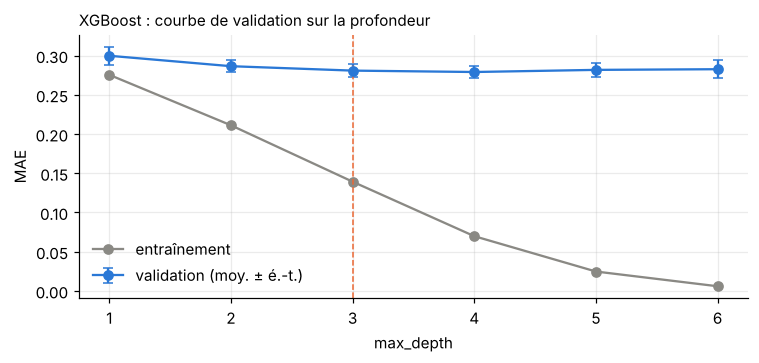

,max_depth,train,val,std
0,1,0.275,0.300,0.011
1,2,0.211,0.286,0.008
2,3,0.139,0.281,0.009
3,4,0.070,0.279,0.007
4,5,0.025,0.282,0.009
5,6,0.006,0.283,0.012


In [ ]:
depths = [1, 2, 3, 4, 5, 6]
vc = []
for d in depths:
    r = M.cv_report(M.make_xgb(**{**xgb_params, "max_depth": d}), train[feat_AB], y, groups, f"depth {d}")
    vc.append({"max_depth": d, "train": r["MAE train"], "val": r["MAE val (moy)"], "std": r["MAE val (é.-t.)"]})
vc = pd.DataFrame(vc)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(vc.max_depth, vc.train, "o-", color=C.C_MUTED, label="entraînement")
ax.errorbar(vc.max_depth, vc.val, yerr=vc["std"], fmt="o-", color=C.C_SIGNAL, capsize=3, label="validation (moy. ± é.-t.)")
ax.axvline(xgb_params["max_depth"], color=C.C_NOISY, ls="--", lw=1)
ax.set_xlabel("max_depth"); ax.set_ylabel("MAE"); ax.legend(frameon=False)
ax.set_title("XGBoost : courbe de validation sur la profondeur", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_xgb_depth.png"); plt.show()
vc.round(3)

**Lecture** : l'erreur d'**entraînement** chute de 0,28 (profondeur 1) à 0,006 (profondeur 6), alors que l'erreur de
**validation** ne bouge presque plus à partir de la profondeur 2 (0,279 à 0,286). À la profondeur 1, le modèle est trop
simple (**sous-apprentissage**, validation 0,30). Au-delà de 3, les arbres apprennent par cœur le bruit des séismes
d'entraînement **sans rien gagner** en validation (**sur-apprentissage**). La profondeur 3 retenue est le bon
compromis : validation 0,281 pour un écart train/validation deux fois plus petit qu'en profondeur 6.

## 6. Tableau comparatif final (validation croisée sur le train)

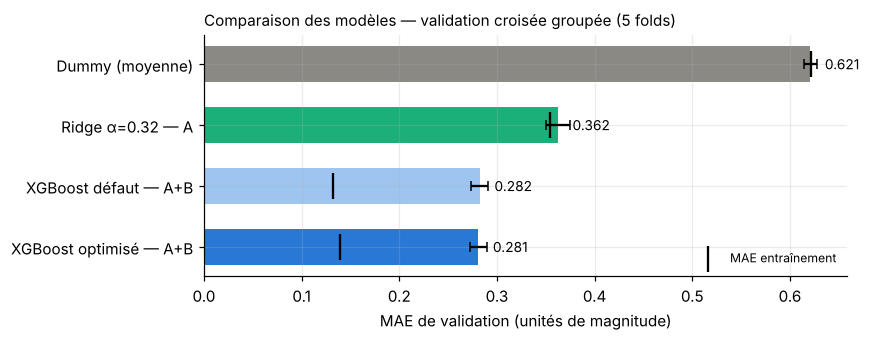

,MAE train,MAE val (moy),MAE val (é.-t.),RMSE train,RMSE val (moy),RMSE val (é.-t.),R2 train,R2 val (moy),R2 val (é.-t.),temps ajust. (s)
modèle,,,,,,,,,,
Dummy (moyenne),0.621,0.621,0.007,0.715,0.715,0.007,0.000,-0.001,0.001,0.003
Ridge α=0.32 — A,0.354,0.362,0.013,0.451,0.462,0.016,0.603,0.581,0.028,0.020
XGBoost défaut — A+B,0.132,0.282,0.009,0.166,0.364,0.012,0.946,0.740,0.016,5.114
XGBoost optimisé — A+B,0.139,0.281,0.009,0.177,0.362,0.014,0.939,0.742,0.019,3.333


In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    final_rows = [M.cv_report(M.make_dummy(), train[feat_A], y, groups, "Dummy (moyenne)"),
                  M.cv_report(M.make_ridge(best_alpha), train[feat_A], y, groups, f"Ridge α={best_alpha:.2g} — A"),
                  M.cv_report(M.make_xgb(), train[feat_AB], y, groups, "XGBoost défaut — A+B"),
                  M.cv_report(M.make_xgb(**xgb_params), train[feat_AB], y, groups, "XGBoost optimisé — A+B")]
final = pd.DataFrame(final_rows).set_index("modèle")
final.to_csv(C.PROJECT_ROOT / "reports" / "03_comparaison_cv.csv")

fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(final))[::-1]
ax.barh(yy, final["MAE val (moy)"], xerr=final["MAE val (é.-t.)"], color=[C.C_MUTED, "#1baf7a", "#9ec5f0", C.C_SIGNAL],
        height=0.6, capsize=3)
ax.scatter(final["MAE train"], yy, marker="|", s=300, color="k", zorder=3, label="MAE entraînement")
for yi, v in zip(yy, final["MAE val (moy)"]):
    ax.text(v + 0.015, yi, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels(final.index); ax.set_xlabel("MAE de validation (unités de magnitude)")
ax.set_title("Comparaison des modèles — validation croisée groupée (5 folds)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_comparaison_modeles.png"); plt.show()
final.round(3)

**Lecture** : 
- **XGBoost optimisé** : MAE = **0,281 ± 0,009** (R² = 0,74), soit **−55 %** d'erreur par rapport au Dummy (0,621)
  et **−22 %** par rapport à Ridge (0,362). C'est le modèle retenu.
- L'optimisation n'améliore **presque pas** le score (0,282 → 0,281, bien moins que l'écart-type) : elle donne surtout
  un modèle **plus simple** (arbres de profondeur 3 au lieu de 4) et **plus rapide** (3,3 s au lieu de 5,1 s).
- **Message clé pour l'oral** : ce sont les signaux eux-mêmes, et non les réglages du modèle, qui limitent la
  performance (cf. section 7).
- RMSE (0,36) > MAE (0,28) : il existe des erreurs **plus grosses que la moyenne**, que l'on regarde ci-dessous.

## 7. Aperçu des erreurs par tranche de magnitude (prédictions hors-fold)

Chaque séisme du train est prédit par le modèle entraîné **sans** son fold (`cross_val_predict`) : c'est une estimation
honnête, sans toucher au test. L'analyse détaillée sera faite sur le test (notebook 04).

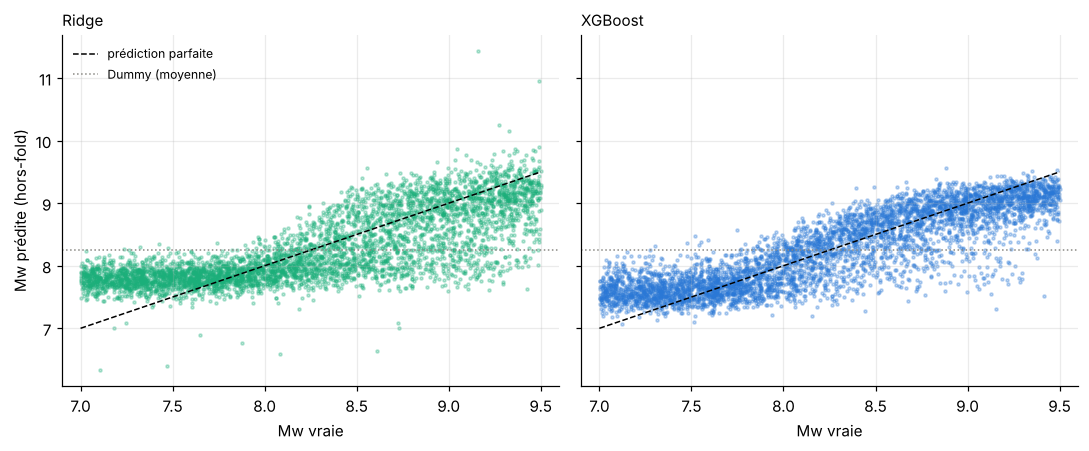

,n,MAE Ridge,MAE XGBoost,biais XGBoost (préd − vraie)
mw,,,,
"(7.0, 7.5]",942,0.538,0.357,0.348
"(7.5, 8.0]",982,0.173,0.194,0.004
"(8.0, 8.5]",947,0.272,0.280,-0.005
"(8.5, 9.0]",992,0.402,0.273,-0.058
"(9.0, 9.5]",937,0.438,0.308,-0.277


In [ ]:
oof = pd.DataFrame({"mw": y, "mecanisme": train.mecanisme})
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    oof["Ridge"] = cross_val_predict(M.make_ridge(best_alpha), train[feat_A], y, groups=groups, cv=M.cv_splitter())
oof["XGBoost"] = cross_val_predict(M.make_xgb(**xgb_params), train[feat_AB], y, groups=groups, cv=M.cv_splitter())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, m, col in zip(axes, ["Ridge", "XGBoost"], ["#1baf7a", C.C_SIGNAL]):
    ax.scatter(oof.mw, oof[m], s=4, alpha=0.3, color=col)
    ax.plot([7, 9.5], [7, 9.5], color="k", lw=1, ls="--", label="prédiction parfaite")
    ax.axhline(y.mean(), color=C.C_MUTED, lw=1, ls=":", label="Dummy (moyenne)")
    ax.set_xlabel("Mw vraie"); ax.set_title(m, loc="left", fontsize=10); ax.set_xlim(6.9, 9.6)
axes[0].set_ylabel("Mw prédite (hors-fold)"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "03_oof_pred_vs_true.png"); plt.show()

bins = pd.cut(oof.mw, np.arange(7, 9.51, 0.5))
per_bin = pd.DataFrame({
    "n": oof.groupby(bins, observed=True).size(),
    "MAE Ridge": oof.assign(e=(oof.Ridge - oof.mw).abs()).groupby(bins, observed=True).e.mean(),
    "MAE XGBoost": oof.assign(e=(oof.XGBoost - oof.mw).abs()).groupby(bins, observed=True).e.mean(),
    "biais XGBoost (préd − vraie)": oof.assign(e=oof.XGBoost - oof.mw).groupby(bins, observed=True).e.mean()})
per_bin.round(3)

**Lecture** : deux phénomènes, présents pour les deux modèles :
1. **Plancher de détection (Mw < 8)** : les prédictions forment une **bande horizontale** autour de Mw ≈ 7,6–7,8,
   quelle que soit la vraie magnitude. Le modèle ne « voit » pas ces séismes (PEGS sous le bruit, notebook 02) et prédit
   la moyenne des séismes invisibles. Il **surestime** donc les Mw 7,0–7,5 (biais +0,35). Attention : la bonne MAE de la
   tranche 7,5–8,0 (0,19) est un **artefact** ; c'est simplement là que tombe cette valeur par défaut.
2. **Sous-estimation des plus grands séismes (Mw > 9)** : biais de **−0,28** en moyenne, avec une traîne de séismes
   prédits vers Mw 8. Causes probables, à vérifier au notebook 04 : (a) à 300 s, la rupture des plus gros séismes n'est
   pas terminée (notebook 01) ; (b) un arbre ne sait pas prédire au-delà des valeurs vues à l'entraînement et « tasse »
   les prédictions vers l'intérieur près de la borne 9,5 ; (c) certains mécanismes ou positions de source sont peu
   favorables.

Entre 8 et 9, XGBoost suit bien la diagonale. Ridge, linéaire, est plus dispersé et produit même des valeurs
**absurdes** (jusqu'à Mw ≈ 11) en extrapolant.

## 8. Entraînement final sur tout le train et sauvegarde

Les modèles retenus sont ré-entraînés sur les 4 800 séismes du train, puis sauvegardés dans `models/`.
Ils seront évalués **une seule fois** sur le test au notebook 04.

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    final_models = {"dummy": (M.make_dummy().fit(train[feat_A], y), feat_A),
                    "ridge": (M.make_ridge(best_alpha).fit(train[feat_A], y), feat_A),
                    "xgboost": (M.make_xgb(**xgb_params).fit(train[feat_AB], y), feat_AB)}
for name, (model, cols) in final_models.items():
    joblib.dump({"model": model, "features": cols, "T_decision": C.T_DECISION}, MODEL_DIR / f"{name}.joblib")
meta = {"ridge_alpha": float(best_alpha), "xgb_params": xgb_params,
        "cv": final[["MAE val (moy)", "MAE val (é.-t.)", "RMSE val (moy)", "R2 val (moy)", "MAE train"]].round(4).to_dict("index")}
(MODEL_DIR / "model_card.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print("Sauvegardé :", sorted(p.name for p in MODEL_DIR.iterdir()))

Sauvegardé : ['dummy.joblib', 'model_card.json', 'ridge.joblib', 'xgboost.joblib']


## 9. Bilan


| Partie | Ce qui a été fait | Résultat (validation croisée, train uniquement) |
|---|---|---|
| Découpage | Train/test séparés par **heures de bruit réel** ; validation croisée `GroupKFold` à 5 folds sur les 18 heures du train | 0 heure commune entre train et validation dans chaque fold |
| Modèles | Dummy, Ridge, XGBoost dans des `Pipeline` ; comparaison des familles A et A+B | Ridge meilleur sur A, XGBoost meilleur sur A+B |
| Optimisation | Ridge : grille sur α ; XGBoost : 20 combinaisons aléatoires + règle d'un écart-type | Dummy **0,621** · Ridge **0,362** · XGBoost **0,281 ± 0,009** |
| Diagnostic | Courbes de validation (α, profondeur) ; erreurs hors-fold par tranche de Mw | XGBoost sur-apprend sans perte en validation ; plancher de détection sous Mw 8 ; sous-estimation au-dessus de Mw 9 |

Les 3 modèles finaux sont dans `models/`. **Le jeu de test n'a pas encore été utilisé** : il le sera au notebook 04, une seule fois.